# Experiment logs

## Images don't always have the EXIF metadata (especially PNGs)

- Images don't always have the EXIF metadata (especially PNGs)
- Images usually get stripped EXIF metadata for privacy reasons because they can reveal sensitive information. Forethat, whene ever an image is shared or maybe stored in kaggle datasets it gets stripped.

In [1]:
import os
from PIL import Image
from datetime import datetime

def get_image_creation_date(image_path):
    try:
        with Image.open(image_path) as img:
            exif_data = img._getexif()

            if exif_data is None:
                print("No EXIF data found.")
                return None

            # 36867 = DateTimeOriginal
            img_time_str = exif_data.get(36867)

            if img_time_str is None:
                print("No DateTimeOriginal in EXIF.")
                return None

            img_time = datetime.strptime(img_time_str, '%Y:%m:%d %H:%M:%S')
            return img_time

    except Exception as e:
        print(f"Error: {e}")
        return None

In [2]:
get_image_creation_date('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/3.jpg')
print('###')
get_image_creation_date('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/0.png')

Error: [Errno 2] No such file or directory: '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/3.jpg'
###
Error: [Errno 2] No such file or directory: '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/0.png'


## Gemini/Gemma Image Prompt Function

- this function calls gemini api with a prompt to describe an image and analyze the visuals inside it.

- we can see that both gemini/gemma models can do the job

- the output of this functino is a parsable text that describe the image.

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("Gemini")

In [4]:
import google.genai as genai
from google.genai.client import Client
# The client gets the API key from the environment variable `GEMINI_API_KEY`.
client = genai.Client(api_key=secret_value_0)

In [5]:
import cv2
from PIL import Image, ImageEnhance, ImageOps
from typing import Union, List
from pathlib import Path
import PIL.Image
import numpy as np


def preprocess_image( image: Union[str, Path, np.ndarray, Image.Image], apply_grey: bool) -> Image.Image:
    """Light preprocessing (contrast boost) to improve OCR accuracy on both engines."""
    if isinstance(image, (str, Path)):
        img = Image.open(image).convert("RGB")
    elif isinstance(image, np.ndarray):
        img = Image.fromarray(image).convert("RGB")
    elif isinstance(image, Image.Image):
        img = image.convert("RGB")
    else:
        raise ValueError(f"Unsupported image type: {type(image)}")
    
    # resize first (important)
    img = img.resize((int(img.width * 1.5), int(img.height * 1.5)), Image.BICUBIC)

    if apply_grey:
        # convert to grayscale
        img = img.convert("L")
  
    # Boost contrast – helps especially with Arabic script and low-quality scans
    img = ImageOps.exif_transpose(img) # Reads EXIF tag Orientation
    enhancer = ImageEnhance.Contrast(img) 
    return enhancer.enhance(2)

In [6]:
def run_client_batch(
    client:Client,
    images: List[PIL.Image.Image], 
    subject: str = "Unkown unfortunately", 
    lecture_title: str = 'Unkown unfortunately', 
    history: List[str] = []
) -> str:
    """
    Processes a batch of images with temporal context and visual grounding.
    """
    for image in images:
        if not isinstance(image,PIL.Image.Image):
            return f"Images should have the type of PIL.Image.Image not {type(image)}"
    
    # 1. Prepare Context (Only last 2 history entries to avoid prompt bloat)
    recent_history = "\n---\n".join(history[-2:]) if history else "Start of lecture."

    # 2. Construct the Systematic Prompt
    prompt = (
        f"SYSTEM: أنت خبير في تفريغ النصوص الأكاديمية لمادة {subject}.\n"
        f"LECTURE: {lecture_title}\n"
        f"RECENT CONTEXT: {recent_history}\n\n"
        "TASK: قم بتحليل الصور المقدمة بالتسلسل. لكل صورة:\n"
        "1. TEXT المستخرج: جميع النصوص كما هي تمامًا. يدعم العربية/الإنجليزية واتجاه RTL.\n"
        "2. العناصر البصرية: اكتشف كل مخطط، رسم، أو شكل معقد. ولكل عنصر بصري، قدم:\n"
        "   - BOX: [ymin, xmin, ymax, xmax] (إحداثيات مطبعة بين 0-1000).\n"
        "   - الوصف: شرح رسمي لمعنى العنصر البصري.\n\n"
        "3. قم بترقيم الصور في هذه الدفعة كالتالي: SLIDE_1, SLIDE_2, SLIDE_3 على الترتيب.\n"
        "تنسيق الإخراج (إلزامي):\n"
        "### SLIDE_[N] ###\n"
        "## TEXT ##\n[النص الخام]\n"
        "## VISUALS ##\n"
        "#\nCOORD: [ymin, xmin, ymax, xmax]\nDESC: [وصف مختصر بالعربية/(مصطلحات إنجليزية) ]\n#\n"
    )

    # Contents: Prompt + the list of images
    contents = [prompt] + images

    try:
        
        response = client.models.generate_content(
            model="gemma-4-31b-it", 
            contents=contents
        )
        return response.text.strip()
    except Exception as e:
        print(f"Batch API error: {e}")
        return f"Error: {e}"

In [7]:
TEST_IMAGES = ['/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg',
               '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png']
test_images_pil = [preprocess_image(img,apply_grey=False) for img in TEST_IMAGES]

In [8]:
output = run_client_batch(client, test_images_pil, subject='Networks', lecture_title='basics of networks' )
print(output)

Batch API error: 500 INTERNAL. {'error': {'code': 500, 'message': 'Internal error encountered.', 'status': 'INTERNAL'}}
Error: 500 INTERNAL. {'error': {'code': 500, 'message': 'Internal error encountered.', 'status': 'INTERNAL'}}


**Result:**

**Gemma4 31b** is very effective for complex hand written Arabic Text. Also, it is very good for detecting and describing complex illustrations.

### Testing gemma-4-e2b-it

I will test **Gemma4 e2b** quantized to 4bits to see if the model will perform good locally

In [9]:
!pip install -U transformers  -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 44.0 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 66.1 MB/s eta 0:00:00ta 0:00:01


In [10]:
pip install -U bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 26.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [11]:
import kagglehub
from time import time
from transformers import AutoProcessor, AutoModelForCausalLM
import torch

In [12]:
import torch
from transformers import AutoProcessor, AutoModelForMultimodalLM, BitsAndBytesConfig
import kagglehub

# Choose your model path
MODEL_NAME = "google/gemma-4/transformers/gemma-4-e2b-it" 


print("Downloading model...")
MODEL_PATH = kagglehub.model_download(MODEL_NAME)

# 1. Setup the BitsAndBytes Configuration
# For 4-bit (Highly recommended for the 26B model on Kaggle's dual T4s)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    llm_int8_skip_modules=[
        "lm_head",
        "audio_tower",
        "embed_audio",
        "model.audio_tower",
        "model.embed_audio",
    ],
)
print("Loading processor...")
processor = AutoProcessor.from_pretrained(MODEL_PATH)

print("Loading model (this will take a moment)...")
# 2. Use AutoModelForMultimodalLM and low_cpu_mem_usage
model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_PATH,
    quantization_config=bnb_config,
    device_map="auto",
    low_cpu_mem_usage=True, # CRITICAL FOR KAGGLE: prevents CPU RAM spikes!
    dtype=torch.bfloat16
)

Loading processor...
Loading model (this will take a moment)...


Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

In [13]:
def run_gemma_batch(
    model,
    processor,
    images: list[Image.Image],
    subject: str = "Unknown unfortunately",
    lecture_title: str = 'Unknown unfortunately',
    history: List[str] = []
) -> str:
    """
    Gemma-4 multimodal batch processor (fully local).
    """
    for image in images:
        if not isinstance(image, Image.Image):
            return f"Images should have the type of PIL.Image.Image not {type(image)}"

    recent_history = "\n---\n".join(history[-2:]) if history else "Start of lecture."

    prompt = (
        f"SYSTEM: You are an academic transcription expert for {subject}.\n"
        f"LECTURE: {lecture_title}\n"
        f"RECENT CONTEXT: {recent_history}\n\n"
        "TASK: Analyze the provided images in sequence. For EACH image:\n"
        "1. EXTRACTED TEXT: All text exactly as shown. Support Arabic/English RTL.\n"
        "2. VISUALS: Detect every diagram, sketch, or complex chart. For each, provide:\n"
        "   - BOX: [ymin, xmin, ymax, xmax] (normalized 0-1000 coordinates).\n"
        "   - DESCRIPTION: Formal explanation of the visual's meaning.\n\n"
        "3. For the images in this batch, number them as SLIDE_1, SLIDE_2, SLIDE_3 respectively.\n"
        "OUTPUT FORMAT (STRICT):\n"
        "### SLIDE_[N] ###\n"
        "## TEXT ##\n[Raw Text]\n"
        "## VISUALS ##\n"
        "#\nCOORD: [ymin, xmin, ymax, xmax]\nDESC: [Brief Description Arabic/(English Terms) ]\n#\n"
    )

    try:
        # Correct way for Gemma-4 multimodal (image tokens)
        content = [{"type": "image", "image": img} for img in images]
        content.append({"type": "text", "text": prompt})

        messages = [{"role": "user", "content": content}]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            return_dict=True,
            return_tensors="pt",
            add_generation_prompt=True,
        ).to(model.device)

        input_len = inputs["input_ids"].shape[-1]

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=4096,
                do_sample=False,
                temperature=0.0,
                num_beams=1,
            )

        generated_tokens = outputs[0][input_len:]
        response = processor.decode(generated_tokens, skip_special_tokens=False)
        
        # Gemma-4 often returns a parsed object
        if hasattr(processor, 'parse_response'):
            parsed = processor.parse_response(response)
            return parsed.text.strip() if hasattr(parsed, 'text') else str(parsed).strip()
        else:
            return response.strip()

    except Exception as e:
        print(f"Batch inference error: {e}")
        return f"Error: {e}"

**I will use Arabic Prompt because by testing I am getting better results when the prompt is in Arabic**

In [14]:
def run_gemma_batch_arabic(
    model,
    processor,
    images: list[Image.Image],
    subject: str = "Unknown unfortunately",
    lecture_title: str = 'Unknown unfortunately',
    history: List[str] = []
) -> str:
    """
    Gemma-4 multimodal batch processor (fully local).
    """
    for image in images:
        if not isinstance(image, Image.Image):
            return f"Images should have the type of PIL.Image.Image not {type(image)}"

    recent_history = "\n---\n".join(history[-2:]) if history else "Start of lecture."

    prompt = (
        f"النظام: أنت خبير في النسخ الأكاديمي لمادة {subject}.\n"
        f"المحاضرة: {lecture_title}\n"
        f"السياق الأخير: {recent_history}\n\n"
        "المهمة: قم بتحليل الصور المقدمة بالتسلسل. لكل صورة على حدة:\n"
        "1. النص المستخرج: استخراج كافة النصوص كما هي مكتوبة تماماً. مع دعم الكتابة من اليمين إلى اليسار (RTL) للغتين العربية والإنجليزية.\n"
        "2. العناصر المرئية: رصد كل رسم توضيحي، مخطط، أو جدول معقد. لكل عنصر، قم بتوفير:\n"
        "   - الإحداثيات (BOX): [ymin, xmin, ymax, xmax] (إحداثيات معيارية من 0-1000).\n"
        "   - الوصف: شرح رسمي لمعنى العنصر المرئي.\n\n"
        "3. بالنسبة للصور في هذه المجموعة، قم بترقيمها كـ SLIDE_1، SLIDE_2، SLIDE_3 على التوالي.\n\n"
        "صيغة المخرجات (التزام صارم):\n"
        "### SLIDE_[N] ###\n"
        "## TEXT ##\n[النص الخام]\n"
        "## VISUALS ##\n"
        "#\n"
        "COORD: [ymin, xmin, ymax, xmax]\n"
        "DESC: [وصف موجز باللغة العربية / (مع المصطلحات الإنجليزية)]\n"
        "#\n"
    )

    try:
        # Correct way for Gemma-4 multimodal (image tokens)
        content = [{"type": "image", "image": img} for img in images]
        content.append({"type": "text", "text": prompt})

        messages = [{"role": "user", "content": content}]

        inputs = processor.apply_chat_template(
            messages,
            tokenize=True,
            return_dict=True,
            return_tensors="pt",
            add_generation_prompt=True,
        ).to(model.device)

        input_len = inputs["input_ids"].shape[-1]

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=4096,
                do_sample=False,
                temperature=0.0,
                num_beams=1,
            )

        generated_tokens = outputs[0][input_len:]
        response = processor.decode(generated_tokens, skip_special_tokens=False)
        
        # Gemma-4 often returns a parsed object
        if hasattr(processor, 'parse_response'):
            parsed = processor.parse_response(response)
            return parsed.text.strip() if hasattr(parsed, 'text') else str(parsed).strip()
        else:
            return response.strip()

    except Exception as e:
        print(f"Batch inference error: {e}")
        return f"Error: {e}"

In [15]:
from time import time
s_time = time()
output = run_gemma_batch_arabic(model, processor, images=test_images_pil, subject='Networks', lecture_title='basics of networks' )
print(output)
e_time = time()
total_time = round(e_time - s_time, 2)
print(f"Total time: {total_time}")

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{'role': 'assistant', 'content': '### SLIDE_1 ###\n## TEXT ##\npipa liza ipa\n## VISUALS ##\n#\nCOORD: [11, 347, 37, 500]\nDESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).\n\n### SLIDE_2 ###\n## TEXT ##\npipa liza ipa\n## VISUALS ##\n#\nCOORD: [46, 347, 72, 500]\nDESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).\n\n### SLIDE_3 ###\n## TEXT ##\npipa liza ipa\n## VISUALS ##\n#\nCOORD: [81, 347, 107, 500]\nDESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).\n\n### SLIDE_4 ###\n## TEXT ##\nالنظام: أنت خبير في النسخ الأكاديمي لمادة Networks.\nالمحاضرة: basics of networks\nالسياق الأخير: Start of lecture.\n## VISUALS ##\n#\nCOORD: [131, 11, 181, 988]\nDESC: نص يمثل سياق المحاضرة: "النظام: أنت خبير في النسخ الأكاديمي لمادة Networks. المحاضرة: basics of networks. السياق الأخير: Start of lecture."\n\n### SLIDE_5 ###\n## TEXT ##\npipa liza ipa\n## VISUALS ##\n#\nCOORD: [193, 347, 219, 500]\nDESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).\n\n### SLIDE_6 ###\n## TEXT #

In [16]:
import ast
output = ast.literal_eval(output)
print(output['content'])

### SLIDE_1 ###
## TEXT ##
pipa liza ipa
## VISUALS ##
#
COORD: [11, 347, 37, 500]
DESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).

### SLIDE_2 ###
## TEXT ##
pipa liza ipa
## VISUALS ##
#
COORD: [46, 347, 72, 500]
DESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).

### SLIDE_3 ###
## TEXT ##
pipa liza ipa
## VISUALS ##
#
COORD: [81, 347, 107, 500]
DESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).

### SLIDE_4 ###
## TEXT ##
النظام: أنت خبير في النسخ الأكاديمي لمادة Networks.
المحاضرة: basics of networks
السياق الأخير: Start of lecture.
## VISUALS ##
#
COORD: [131, 11, 181, 988]
DESC: نص يمثل سياق المحاضرة: "النظام: أنت خبير في النسخ الأكاديمي لمادة Networks. المحاضرة: basics of networks. السياق الأخير: Start of lecture."

### SLIDE_5 ###
## TEXT ##
pipa liza ipa
## VISUALS ##
#
COORD: [193, 347, 219, 500]
DESC: صورة لشخصية "pipa liza ipa" (صورة رمزية أو خلفية).

### SLIDE_6 ###
## TEXT ##
pipa liza ipa
## VISUALS ##
#
COORD: [228, 347, 254, 500]
DESC: صورة لشخصية

In [17]:
gemma_e2b_4bit_output_handwritten ="""
### SLIDE_1 ###
## TEXT ##
شبكات وإيبيبات topology ring
شبكات
* إيبيبات البيانات كما هو
* تكلفة إيبيبات بين الموصلات والمفتاح
* * تكلفة إيبيبات يؤدي إلى توصيل
* * data collision
* * صناعة فقد البيانات
* * يؤدي إلى عدم التوافق
L = n(n-1)/2
شبكات
* تكلفة محبة
* * مغيرة محبة
* * شبانة وغيره
* * أداء معقد
* * أداء أفضل
## VISUALS ##
#
COORD: [100, 110, 130, 480]
DESC: رسم تخطيطي يوضح مخطط شبكة حلقية (ring topology) مع بعض الرموز التوضيحية.
#

### SLIDE_2 ###
## TEXT ##
HYBRID NETWORK TOPOLOGY
A hybrid topology is a type of network topology that combines two or more network topologies, including ring, bus, and mesh topologies
prepared by Dr. Imad M. Damascus university 2025/2026
## VISUALS ##
#
COORD: [265, 110, 720, 880]
DESC: مخطط يوضح مفهوم "Hybrid Network Topology" (طوبولوجيا الشبكة الهجينة) ويشرح أنها تجمع بين طوبولوجيات متعددة مثل الحلقية (ring)، والناقل (bus)، والشبكة المتشابكة (mesh).
#
"""

The performance is not good. I will see if the model was able to detect the visuals coords correctly

**Next Experiment** : trying the model on simpler images (Arabic but not handwritten)

-------
I will test Gemma4 e2b 4bit on **sample 2** which contain Arabic but not handwritten.

In [18]:
# S2 Arabic word slides samples
TEST_IMAGES_S2 = ['/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_2/images/0.png','/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_2/images/1.png']
test_images_pil_s2 = [preprocess_image(img,apply_grey=False) for img in TEST_IMAGES_S2]

In [19]:
from time import time
s_time = time()
output_s2 = run_gemma_batch_arabic(model, processor, images=test_images_pil_s2, subject='مشروع تخرج', lecture_title='سطح تفاعلي بديل لشاشة اللمس لجعل عملية التعليم اكثر تفاعلية' )
print(output_s2)
e_time = time()
total_time = round(e_time - s_time, 2)
print(f"Total time: {total_time}")

{'role': 'assistant', 'content': '### SLIDE_1 ###\n## TEXT ##\nipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipi

In [20]:
import ast
output_s2 = ast.literal_eval(output_s2)
print(output_s2['content'])

### SLIDE_1 ###
## TEXT ##
ipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipipi

In [21]:
gemma_e2b_4bit_output_s2 = """
### SLIDE_1 ###
## TEXT ##
المقدمة :
السطح التفاعلي هو تطبيق صمم لإحداث نقلة في طريقة تقديم العروض التقديمية في مجال
التعليم والتدريس، حيث يمكن التطبيق على سطح عادي ويجبه يمكن التفاعل معها
مع طرق اللمس والإيماءات، يهدف التطبيق على استخدام كاميرا جهاز كمبيوتر محمول، مما
يلغي الحاجة إلى الشاشات التي تعمل باللمس التي تأتي بخطية التمن.
من خلال الاستفادة من خواص الذكاء الاصطناعي، يضمن التطبيق تجربة مستخدم سلسة،
حيث يوفر تقنيًا دقيقًا للمس والتحدث عن طريق الإيماءات لتعبير اللمس.
وبفضل المزايا التفاعلية والاستجابة الفورية، يضمن هذا التطبيق بديلًا فعالًا من حيث
التكلفة وتعدد استخدامات الطلاب للتطبيق التعليمي، مما يجعل تقنية اللمس المقدمة في متناول
أوسع من المستخدمين في كافة القطاعات.
تمثل هذه التقنية فائدة كبيرة للمتعلمين ومقدمي الأخير والمدربين في الشركات وغيرهم من
المؤسسات الذين يسعون لتوفير أجر وخدمة أفضل وفاعلية، كما يمكن التبليغ بالتطبيق
بإرساله مع البرامج المستخدمة، مثل PowerPoint و Microsoft و PowerPoint و تطبيقات أخرى،
مما يساح للمستخدمين بالحفاظ على سير العمل المعتاد مع الاستفادة من الميزات التفاعلية
للتطبيق.
دوافع العمل:
- الكفاءة التفاعلية للشاشات الذكية، مما يجعله غير متاح لجميع المستخدمين.
- الحجم الثابت للشاشات العرض الذكية، مما يجعله من أمكنة استخدامها في جميع البيئات.
- سهلة التفاعل أثناء العروض التي يقدمها تطبيق إلى فقيان أثناء انتباه الجمهور وتفعيل التأثير أثناء
العرض لمحدودية المستخدم.
الأهداف:
- تزويد المتعلم عن العروض التقديمية من خلال تحويل أي سطح إلى واجهة تفاعلية، مما يجعل العروض أكثر
ديناميكية وجاذبية.
- اختصار وقت العرض و زيادة كفاءته بشكل مباشر مع العرض دون الحاجة للعودة إلى جهاز الحاسوب.
- تقليل التكلفة المشاركة لشراء الشاشات الذكية. حيث يقدم التطبيق بديلًا اقتصاديًا وفعالًا.
- الاستفادة من تقنيات الذكاء الاصطناعي والرؤية في محاللات التعليم والعرروض التقديمية لتحسين
التفاعل وتقديم تجربة أكثر حداثة.
- دعم التفاعل بالإيماءات مما يوفر أساليب تحكم غير لمسية للمستخدمين تجربة استخدام مرنة
ومبتكرة.
## VISUALS ##
#

### SLIDE_2 ###
## TEXT ##
الدراسة المرجعية :
الجزء الأول: التعرف على الإيماءات
مقدمة :
بدء التعرف على الإيماءات محلًا مهما في معالجة الصور ورؤية الحاسوب، حيث يهدف إلى تفسير حركات اليد
أو الجزء المخدد للتكتم في الطريقة الرقمية، ترتكز هذه التقنية على خوارزميات تعلم الآلة (Machine
learning) و الخوارزميات لاستخراج وتفعيل معالم الإيماءات من الصور أو الفيديو هات. يستخدم التعرف
على الإيماءات في تطبيقات متنوعة متنوعة مثل التفاعل مع الأجهزة الذكية، الواقع المعزز(AR) والتطبيقات التي لا تعتمد
على اللمس.
## VISUALS ##
#
COORD: [398, 118, 675, 879]
DESC: [مخطط يوضح مراحل اكتشاف الإيماءات: معالجة الصورة، اكتشاف اليد، وتصنيف الإيماءة.]

### SLIDE_3 ###
## TEXT ##
القسم الأول: Hand detection
يعد اكتشاف اليد الخطوة الأولى في نظام التعرف على الإيماءات، تتضمن هذه العملية تحديد وجود اليد
وموقعها في الصورة، مما يشكل الخطوة الأساسية لاستخراج معالم اليد و من تم التعرف على الإيماءات،
اعتمدت الأساليب التقليدية على مستشعرات العمق أو نماذج عالية التكلفة حسابيًا، لكن الأساليب الحديثة،
دقيق وسريع للبدء باستخدام كاميرا فقط.
التقنية الأولية: Skin-based
تم إقرار طريقة لتتبع اليد في بيئة شبه ثابتة [1] حيث تكون اليد فقط ضمن نطاق رؤية، باستخدام مكتبة
OpenCV يتم تطبيق إزالة الخلفية عبر تقنيات بسيطة، تليها معالجة من المرشحات لاستخلاص محيط اليد.
## VISUALS ##
#
COORD: [845, 35, 913, 964]
DESC: [مخطط يوضح مسار اكتشاف الإيماءات: معالجة الصورة (image preprocessing)، اكتشاف اليد (Hand Detection)، وتصنيف الإيماءة (Gesture classification).]
"""

**The model performance on Microsoft Word type of text is good, but there is some mistakes right now and sometimes small mistakes can result in very big meaning shift and education OCR needs to be preicse**

------

## VLM Output Parser Function

The output has the following structure:

```text
### SLIDE_1 ###
## TEXT ##
[extratcted text here]

## VISUALS ##
# 
COORD: [first visualization coordination]
DESC: [the visualization description]
#
COORD: [second visualization coordination]
DESC: [the visualization description]
#
### SLIDE_2 ###
.
.
.
```


In [22]:
OUTPUT_EXAMPLE_1 = '### SLIDE_1 ###\n## TEXT ##\nسلبيات وإيجابيات ring topology\n\nإيجابيات:\n* نحتاج إلى كبل واحد فقط\n* تكلفة قليلة\n* ما في data collision\n* إضافة عقدة جديدة\n\nسلبيات:\n* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل\n* أي تعطل في الكبل يؤدي إلى توقف النظام كامل\n* bandwidth بطيئة\n\nسلبيات وإيجابيات mesh topology\n\nقانون عدد التوصيلات\nL = n(n-1)/2\n\nإيجابيات:\n* لا يوجد نقطة فشل واحدة\nNo single point of failure\n* أداء ممتاز\n* أمانه أفضل\n\nسلبيات:\n* تكلفة عالية جداً\n* غير عملية للشبكات الكبيرة\n* صيانة معقدة\n* نحتاج عدد كبير من المنافذ\n\n## VISUALS ##\n#\nCOORD: [90, 85, 210, 365]\nDESC: رسم تخطيطي لشبكة حلقية (Ring Topology) تظهر الأجهزة متصلة في حلقة مغلقة.\n#\nCOORD: [320, 0, 400, 185]\nDESC: صندوق يحتوي على الصيغة الرياضية لحساب عدد الوصلات في شبكة مشبكية (Mesh Topology Connections Formula): L = n(n-1)/2.\n#'

In [23]:
OUTPUT_EXAMPLE_2 = """### SLIDE_1 ###
## TEXT ##
سلبيات وإيجابيات ring topology
سلبيات
* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل
* أي تعطل في الكبل يؤدي إلى توقف النظام كامل
إيجابيات
* نحتاج إلى كبل واحد فقط
* تكلفة قليلة
* ما في data collision
* إضافة عقد جديدة
لا يؤثر على الـ bandwidth بسيطة

قانون عدد التوصيلات
L = n(n-1) / 2

سلبيات وإيجابيات mesh topology
إيجابيات
* لا يوجد نقطة فشل واحدة No single point of failure
* أداء ممتاز
* أمانه أفضل
سلبيات
* تكلفة عالية جداً
* غير عملية للشبكات الكبيرة
* صيانة معقدة
* تحتاج عدد كبير من المنافذ

CASTLE Rasheed
## VISUALS ##
#
COORD: [88, 85, 210, 358]
DESC: رسم تخطيطي لشبكة حلقية (Ring Topology) تظهر الأجهزة متصلة في حلقة مغلقة.
#
COORD: [321, 2, 398, 184]
DESC: صندوق يحتوي على الصيغة الرياضية لحساب عدد الوصلات في شبكة مشبكية (Mesh Topology Connections Formula): L = n(n-1)/2.
#

### SLIDE_2 ###
## TEXT ##
HYBRID NETWORK TOPOLOGY
A hybrid topology is a type of network topology that combines two or more network topologies, including ring, bus, and mesh topologies
prepared by Dr. Imad M. Damascus university 2025/2026
zenarmor
## VISUALS ##
#
COORD: [475, 82, 880, 941]
DESC: مخطط يوضح طبولوجيا الشبكة الهجينة (Hybrid Topology)، حيث يدمج بين عدة أنواع من الطبولوجيا (مثل Star و Ring و Bus) متصلة عبر جهاز مركزي.
#"""
print(OUTPUT_EXAMPLE_2)

### SLIDE_1 ###
## TEXT ##
سلبيات وإيجابيات ring topology
سلبيات
* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل
* أي تعطل في الكبل يؤدي إلى توقف النظام كامل
إيجابيات
* نحتاج إلى كبل واحد فقط
* تكلفة قليلة
* ما في data collision
* إضافة عقد جديدة
لا يؤثر على الـ bandwidth بسيطة

قانون عدد التوصيلات
L = n(n-1) / 2

سلبيات وإيجابيات mesh topology
إيجابيات
* لا يوجد نقطة فشل واحدة No single point of failure
* أداء ممتاز
* أمانه أفضل
سلبيات
* تكلفة عالية جداً
* غير عملية للشبكات الكبيرة
* صيانة معقدة
* تحتاج عدد كبير من المنافذ

CASTLE Rasheed
## VISUALS ##
#
COORD: [88, 85, 210, 358]
DESC: رسم تخطيطي لشبكة حلقية (Ring Topology) تظهر الأجهزة متصلة في حلقة مغلقة.
#
COORD: [321, 2, 398, 184]
DESC: صندوق يحتوي على الصيغة الرياضية لحساب عدد الوصلات في شبكة مشبكية (Mesh Topology Connections Formula): L = n(n-1)/2.
#

### SLIDE_2 ###
## TEXT ##
HYBRID NETWORK TOPOLOGY
A hybrid topology is a type of network topology that combines two or more network topologies, including ring, bus, and mesh

In [24]:
from typing import List, Dict, Any
import re
import ast

def vlm_output_parser(vlm_output_text: str) -> List[Dict[str, Any]]:
    """
    Parses the strict VLM output structure (Gemma 4 or Gemini) into clean, 
    easy-to-use Python data.
    
    Input format (exactly as you showed):
    ## TEXT ##
    [extracted text here]

    ## VISUALS ##
    # 
    COORD: [ymin, xmin, ymax, xmax]
    DESC: [description]
    #
    COORD: [ymin, xmin, ymax, xmax]
    DESC: [description]
    #
    ...

    Returns:
        List[Dict] - one dict per slide
        [
            {
                "text": "full raw text with Arabic/English...",
                "visuals": [
                    {"coord": [90, 85, 210, 365], "desc": "Ring topology diagram..."},
                    {"coord": [320, 0, 400, 185], "desc": "Mesh formula box..."}
                ]
            },
            ...
        ]
    """
    slides: List[Dict[str, Any]] = []
    
    # Split by slide headers (captures the number)
    slide_blocks = re.split(r'### SLIDE_(\d+) ###', vlm_output_text.strip()) # ['', '1', 'content', '2', 'content']

    for i in range(1, len(slide_blocks), 2):
        content = slide_blocks[i + 1]
        
        # Separate TEXT and VISUALS
        if "## VISUALS ##" in content:
            text_part, visuals_part = content.split("## VISUALS ##", 1)
        else:
            text_part = content
            visuals_part = ""
        
        text = text_part.replace("## TEXT ##", "").strip()
        
        # Parse every visual block
        visuals: List[Dict[str, Any]] = []
        # Regex finds COORD + DESC pairs reliably
        pattern = r'COORD:\s*(\[.*?\])\s*DESC:\s*(.*?)(?=\s*#|\Z)'
        matches = re.findall(pattern, visuals_part, re.DOTALL | re.MULTILINE)
        
        for coord_str, desc in matches:
            try:
                coord = ast.literal_eval(coord_str.strip())
                visuals.append({
                    "coord": coord,
                    "desc": desc.strip()
                })
            except:
                continue  # skip any malformed line
        
        slides.append({
            "text": text,
            "visuals": visuals
        })
    
    return slides

In [25]:
parser_output = vlm_output_parser(OUTPUT_EXAMPLE_2)
parser_output

[{'text': 'سلبيات وإيجابيات ring topology\nسلبيات\n* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل\n* أي تعطل في الكبل يؤدي إلى توقف النظام كامل\nإيجابيات\n* نحتاج إلى كبل واحد فقط\n* تكلفة قليلة\n* ما في data collision\n* إضافة عقد جديدة\nلا يؤثر على الـ bandwidth بسيطة\n\nقانون عدد التوصيلات\nL = n(n-1) / 2\n\nسلبيات وإيجابيات mesh topology\nإيجابيات\n* لا يوجد نقطة فشل واحدة No single point of failure\n* أداء ممتاز\n* أمانه أفضل\nسلبيات\n* تكلفة عالية جداً\n* غير عملية للشبكات الكبيرة\n* صيانة معقدة\n* تحتاج عدد كبير من المنافذ\n\nCASTLE Rasheed',
  'visuals': [{'coord': [88, 85, 210, 358],
    'desc': 'رسم تخطيطي لشبكة حلقية (Ring Topology) تظهر الأجهزة متصلة في حلقة مغلقة.'},
   {'coord': [321, 2, 398, 184],
    'desc': 'صندوق يحتوي على الصيغة الرياضية لحساب عدد الوصلات في شبكة مشبكية (Mesh Topology Connections Formula): L = n(n-1)/2.'}]},
 {'text': 'HYBRID NETWORK TOPOLOGY\nA hybrid topology is a type of network topology that combines two or more network topologies, includi

In [26]:
gemma_e2b_4bit_output_handwritten_pasred = vlm_output_parser(gemma_e2b_4bit_output_handwritten)

## Drawing bounding boxes and describe each visualization using a VLM

- One of the great things a VLM can do is to give describing any vizualization in an image and give the coordination of each one.

### Bounding boxes drawing method

this method will take the image and bounding boxes coordinations to draw the boxes on top of the image.

In [27]:
TEST_IMAGES = ['/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg',
               '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png']
test_images_pil = [preprocess_image(img,apply_grey=False) for img in TEST_IMAGES]

In [28]:
from PIL import Image, ImageDraw, ImageFont
import random
from typing import List, Union

def draw_boxes(
    image: Union[str, Image.Image],
    boxes: List[List[int]],
    width: int = 3,
    with_labels: bool = False
):
    """
    Draw boxes where coords are:
    [ymin, xmin, ymax, xmax] normalized in range 0–1000
    """

    # Load image if path
    if isinstance(image, str):
        img = Image.open(image).convert("RGB")
    else:
        img = image.copy()

    W, H = img.size
    draw = ImageDraw.Draw(img)
    
    def get_color(i, total):
        import colorsys
        hue = i / total
        rgb = colorsys.hsv_to_rgb(hue, 1, 1)
        return tuple(int(c * 255) for c in rgb)
    
    for i, box in enumerate(boxes):
        ymin, xmin, ymax, xmax = box

        # Convert normalized → pixel coordinates
        x1 = int((xmin / 1000) * W)
        y1 = int((ymin / 1000) * H)
        x2 = int((xmax / 1000) * W)
        y2 = int((ymax / 1000) * H)

        color = get_color(i, len(boxes))

        draw.rectangle([x1, y1, x2, y2], outline=color, width=width)

        if with_labels:
            draw.text((x1, max(0, y1 - 12)), f"Box {i+1}", fill=color)

    return img

[[88, 85, 210, 358]]
[[88, 85, 210, 358], [321, 2, 398, 184]]
[[475, 82, 880, 941]]
{'/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg': [[88, 85, 210, 358], [321, 2, 398, 184]], '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png': [[475, 82, 880, 941]]}
dict_items([('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg', [[88, 85, 210, 358], [321, 2, 398, 184]]), ('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png', [[475, 82, 880, 941]])])


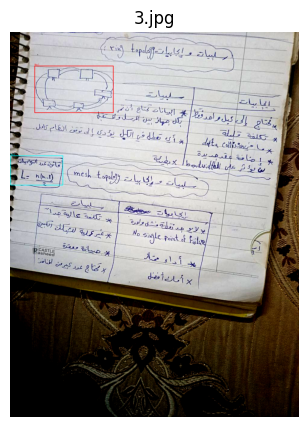

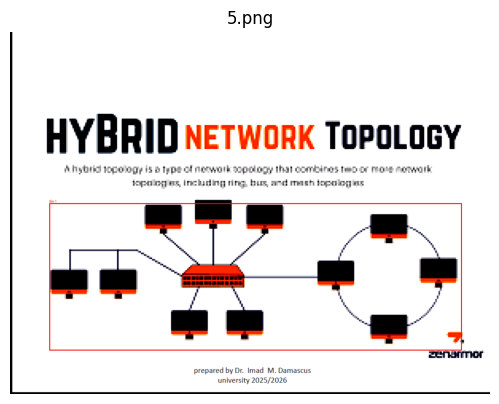

In [29]:
import matplotlib.pyplot as plt
from collections import defaultdict

coords = defaultdict(list)
##
# coords is a dictionary. The keys are the image path and the values are the coordination of bounding boxes inside the image
##
for slide,path in zip(parser_output,TEST_IMAGES):
    slide_visual_coords = []
    for visual in slide['visuals']:
        slide_visual_coords.append(visual['coord'])
        print(slide_visual_coords)
    coords[path] = slide_visual_coords
coords = dict(coords)
print(coords)
print(coords.items())
### plotting ####

cols = 3  

for idx, (img_path, slide_coords) in enumerate(coords.items()):
    
    num_images = len(slide_coords)
    rows = (num_images + cols - 1) // cols
    plt.figure(figsize=(15, 5 * rows))

    plt.subplot(rows, cols, idx + 1)
    
    img = draw_boxes(preprocess_image(img_path,apply_grey=False), slide_coords, with_labels=True)

    plt.imshow(img)
    plt.title(img_path.split("/")[-1])
    plt.axis("off")

plt.tight_layout()
plt.show()

---------------- Gemma4 e2b 4Q ---------------
[[100, 110, 130, 480]]
[[265, 110, 720, 880]]
{'/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg': [[100, 110, 130, 480]], '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png': [[265, 110, 720, 880]]}
dict_items([('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/3.jpg', [[100, 110, 130, 480]]), ('/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/images/5.png', [[265, 110, 720, 880]])])


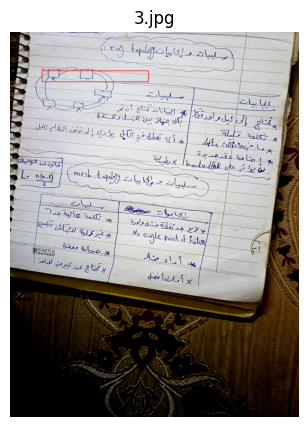

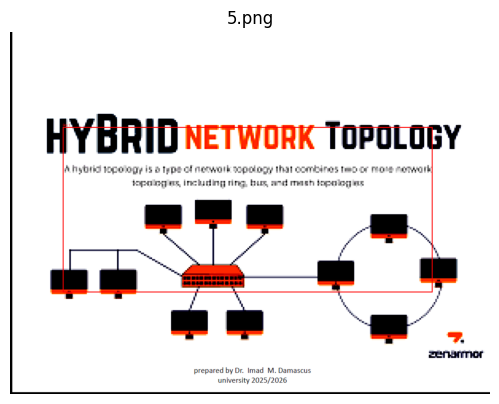

In [30]:
print("---------------- Gemma4 e2b 4Q ---------------")


import matplotlib.pyplot as plt
from collections import defaultdict

coords = defaultdict(list)
##
# coords is a dictionary. The keys are the image path and the values are the coordination of bounding boxes inside the image
##
for slide,path in zip(gemma_e2b_4bit_output_handwritten_pasred,TEST_IMAGES):
    slide_visual_coords = []
    for visual in slide['visuals']:
        slide_visual_coords.append(visual['coord'])
        print(slide_visual_coords)
    coords[path] = slide_visual_coords
coords = dict(coords)
print(coords)
print(coords.items())
### plotting ####

cols = 3  

for idx, (img_path, slide_coords) in enumerate(coords.items()):
    
    num_images = len(slide_coords)
    rows = (num_images + cols - 1) // cols
    plt.figure(figsize=(15, 5 * rows))

    plt.subplot(rows, cols, idx + 1)
    
    img = draw_boxes(preprocess_image(img_path,apply_grey=False), slide_coords, with_labels=True)

    plt.imshow(img)
    plt.title(img_path.split("/")[-1])
    plt.axis("off")

plt.tight_layout()
plt.show()

**The detection is not good also**

I can't rely on Gemma e2b for visual detection

## Gemma 4 e2b Q4 ASR performance

In [34]:
# import soundfile as sf
# audio_path = "/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/ring_tree_topology.wav"

# audio_array, sample_rate = sf.read(audio_path)

# # Important: Convert to proper format for Gemma
# if len(audio_array.shape) > 1:           # stereo → mono
#     audio_array = np.mean(audio_array, axis=1)

# if sample_rate != 16000:
#     # Resample to 16kHz (you can use librosa or torchaudio)
#     import librosa
#     audio_array = librosa.resample(audio_array, orig_sr=sample_rate, target_sr=16000)

In [42]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "استخرج النص من ملف الصوت. /n حافظ على المصطلحات الاجنبية /n لا تضع اسطر جديدة"},
            # {"type": "audio", "audio": audio_array},
            {"type": "audio", "audio": f"/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Samples/sample_1/ring_tree_topology.wav"},
        ]
    }
]

input_ids = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True, return_dict=True,
        return_tensors="pt",
)
input_ids = input_ids.to(model.device, dtype=model.dtype)

outputs = model.generate(**input_ids,temperature=0.0, do_sample=False, max_new_tokens=512)

text = processor.batch_decode(
    outputs,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]
if "model" in text:
    transcription = text.split("model")[-1].strip()
else:
    transcription = text.strip()
print(transcription)

تمام واضح شو دور ديتيرمينيتور هاي تيرمينيتور طيب هلا انا بدي اروح على الشكل عادي بالرينك تابلوجي لاحظ شايفين هلق هذا الشكل موجود معي انا هون هلا انا بدي شيل هذا التيرمينيتور مع هذا التيرمينيتور وبدي اربطو لهذا بدي اربط النهايه هذا مع البدايه هذا ما صار عندي عباره عن عباره عن حلقه هذا بنسميه رينك تابلوجي الرينك تابلوجي


**Surprisingly the model perfomance is very good on Arabic ASR. The only improvement needed for the model is to be code-switching**
